# Workshop 2

**Name:** Ramitha Chowdary S  
**Register Number:** 212224240130


In [1]:
import time
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO


In [2]:
model = YOLO("yolov8n.pt")


In [3]:
cap = cv2.VideoCapture(0)
frames = []
for shot in range(3):
    start = time.time()
    frame = None
    while time.time() - start < 5:
        ok, frame = cap.read()
        if not ok:
            break
    frames.append(frame)
cap.release()

Scene 1
person 0.94
chair 0.35
Scene 2
person 0.77
Scene 3
cell phone 0.92
person 0.90
chair 0.31


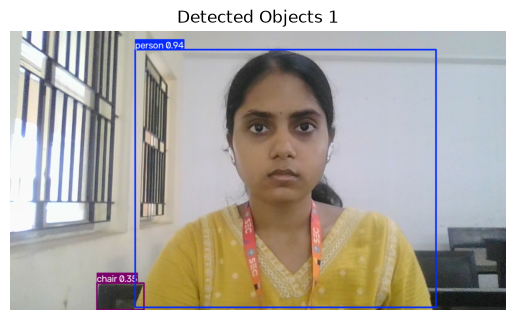

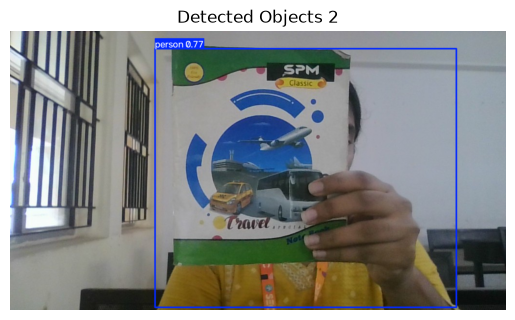

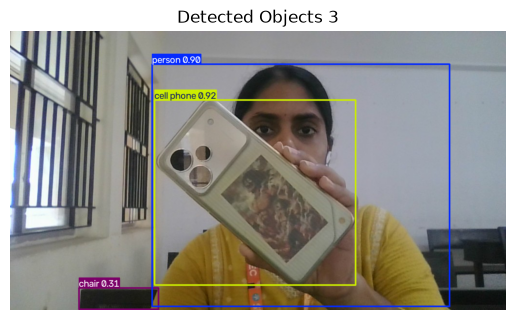

In [4]:
for shot, frame in enumerate(frames, 1):
    detected = model.predict(frame, verbose=False)[0]
    print(f"Scene {shot}")
    for box in detected.boxes:
        print(detected.names[int(box.cls)], round(float(box.conf), 2))
    drawn = detected.plot()
    cv2.imwrite(f"output/0{shot}-detected.png", drawn)
    plt.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
    plt.title(f"Detected Objects {shot}")
    plt.axis("off")
    plt.show()